# 20 — Follow-up chat, evidence and human judgment

**Question:** did the assistant change the intended setting, and what can we conclude?

A chat turn is not evidence of correctness. We will compare a baseline with a follow-up, test deliberately invalid plans, and construct a human-review record. This is a small demonstration of **AI-assisted geospatial reasoning**, not a trained world model, climate forecast or autonomous health decision system.


## Start here: the question behind the code

**What changed, and what can we responsibly conclude?**

**What you will learn:** revise → compare → challenge → reflect. The numbered reading guides below follow the actual code cells. Read a guide, predict the output, then run its cell with **Shift+Enter**. Run from top to bottom; changing an upstream value requires rerunning the cells that use it.

**GeoAI connection:** A follow-up planning exercise plus deterministic checks and human review; not a world model or clinical system.

**Why this is useful:** An evidence card connects a map operation to provenance, limits, alternatives and a named human review step.

**Where the work happens:** Python compares feature sets and rejects invalid plans. A local Ollama follow-up is optional and clearly labeled.

![From chat to checked evidence. Give the assistant only the checked state needed for a follow-up. Inspect membership as well as the seven-to-four count change. Demonstrate rejection of unknown layers, URLs and unsafe values. Record evidence and disagreement without pretending to validate a health model.](assets/learning/20/infographic.svg)

### Watch the idea unfold

[![Preview: From chat to checked evidence — 32-second captioned walkthrough](assets/learning/20/poster.png)](https://jltobias.github.io/JupyterLite-GeoLibre-GeoAI/lite/files/assets/learning/20/watch.html)

[▶ Watch the captioned mini-video and read its transcript](https://jltobias.github.io/JupyterLite-GeoLibre-GeoAI/lite/files/assets/learning/20/watch.html) · [Launch this notebook](https://jltobias.github.io/JupyterLite-GeoLibre-GeoAI/lite/lab/index.html?path=20_ollama_evidence_review.ipynb) · [Read this Book chapter](https://jltobias.github.io/JupyterLite-GeoLibre-GeoAI/notebooks/20_ollama_evidence_review.html) · [Python and browser learning guide](https://jltobias.github.io/JupyterLite-GeoLibre-GeoAI/learning-guide.html)

The video is a silent four-step teaching storyboard with player controls and captions. Open the companion page to play, pause, seek or download it. The local copy is bundled under `assets/learning/20/`; downloaded media can be played offline. The infographic and the text below cover the same ideas without a video player.

**Video transcript:**

1. **Revise (0–8 s):** Give the assistant only the checked state needed for a follow-up. Code landmark: `current_plan=baseline`.

2. **Compare (8–16 s):** Inspect membership as well as the seven-to-four count change. Code landmark: `after_ids <= before_ids`.

3. **Challenge (16–24 s):** Demonstrate rejection of unknown layers, URLs and unsafe values. Code landmark: `validate_plan(candidate)`.

4. **Reflect (24–32 s):** Record evidence and disagreement without pretending to validate a health model. Code landmark: `human_approved_for_operational_use`.


### Code guide 1 — Prepare the browser and local-service tools

**Read the Python:** The runtime check installs browser-compatible map and plotting packages only in Pyodide. Imports expose the local helper functions. No network request to Ollama occurs in this setup cell.

**Look for:** Plotting, map-building and optional local-model functions are ready.

**Pause and try:** Which packages render a map, and which helper will contact Ollama only when explicitly called?


In [1]:
import sys, json
from pathlib import Path
if sys.platform == "emscripten":
    import micropip
    await micropip.install(["geolibre==3.0.0", "anywidget"])
    from pyodide import loadPackage
    await loadPackage("matplotlib")
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from IPython.display import display, Markdown, FileLink
from ollama_mapping import (BASE_URL, MODEL, FIXTURE_PLAN, COLORS, diagnose,
    synthetic_cells, validate_plan, preview_plan, apply_plan, demo_map, propose_map)
print("Browser" if sys.platform == "emscripten" else "Ordinary Python", "— no model request made")


Ordinary Python — no model request made


### Code guide 2 — Carry forward checked state

**Read the Python:** The follow-up includes a validated previous plan. It requests two changes: raise the cutoff and flatten the view. Live errors stop the cell; the fixture is a separate, explicit default.

**Look for:** Before and after settings, with the response source named.

**Pause and try:** Which two fields should remain unchanged?


In [2]:
baseline = validate_plan(dict(FIXTURE_PLAN))
LIVE_MODEL = False
followup = None
prompt = "Keep the same layer and orange color. Raise the minimum heat proxy to 41 and return to a flat map."
if LIVE_MODEL:
    followup = await propose_map(prompt, current_plan=baseline, model=MODEL, base_url=BASE_URL)
else:
    followup = {"source": "hand-authored fixture; NOT a captured AI answer",
                "plan": {**baseline, "minimum_heat": 41, "pitch": 0}}
revised = validate_plan(followup["plan"])
print(json.dumps({"source": followup["source"], "before": baseline, "after": revised}, indent=2))


{
  "source": "hand-authored fixture; NOT a captured AI answer",
  "before": {
    "layer": "synthetic_cells",
    "minimum_heat": 39,
    "color": "orange",
    "pitch": 45
  },
  "after": {
    "layer": "synthetic_cells",
    "minimum_heat": 41,
    "color": "orange",
    "pitch": 0
  }
}


### Code guide 3 — Compare computed evidence

**Read the Python:** Sets make membership and differences explicit. The checks compare the model's settings with an independently authored expected answer. The bar height is a computed feature count, not an estimate of people.

**Look for:** Seven cells before and four after for the supplied task.

**Pause and try:** If counts match but color does not, did the assistant follow the whole request?


{'requested_settings_match': True, 'computed_counts_match': True, 'selection_is_subset': True} | Removed: ['cell-0-2', 'cell-1-2', 'cell-2-1']


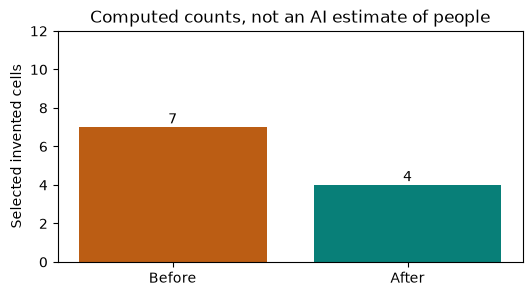

In [3]:
before_ids = {f["id"] for f in preview_plan(baseline)["features"]}
after_ids = {f["id"] for f in preview_plan(revised)["features"]}
expected = {**baseline, "minimum_heat": 41, "pitch": 0}
checks = {"requested_settings_match": revised == expected,
          "computed_counts_match": (len(before_ids), len(after_ids)) == (7, 4),
          "selection_is_subset": after_ids <= before_ids}
print(checks, "| Removed:", sorted(before_ids-after_ids))
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(["Before", "After"], [len(before_ids), len(after_ids)], color=["#bb5d14", "#087f78"])
ax.set(ylim=(0, 12), ylabel="Selected invented cells", title="Computed counts, not an AI estimate of people")
for index, count in enumerate([len(before_ids), len(after_ids)]):
    ax.text(index, count+.2, str(count), ha="center")
plt.show()


### Code guide 4 — Try plans that must fail

**Read the Python:** Each test adds an unknown URL, non-finite number, invalid camera angle or invented layer. `try/except` shows rejection without stopping the entire lesson. A separate test exercises the human approval gate.

**Look for:** Four rejected plans and one blocked application.

**Pause and try:** Why does checking a schema help without proving the remaining plan is scientifically appropriate?


In [4]:
invalid_plans = [
    {**baseline, "url": "https://example.invalid/patient-data"},
    {**baseline, "minimum_heat": float("nan")},
    {**baseline, "pitch": 90},
    {**baseline, "layer": "imagined_flood_predictions"},
]
for candidate in invalid_plans:
    try:
        validate_plan(candidate)
        raise AssertionError("Invalid plan was accepted")
    except ValueError as error:
        print("Rejected:", error)
try:
    apply_plan(baseline)  # No approval means no application.
except PermissionError as error:
    print("Approval gate:", error)


Rejected: Plan must contain exactly layer, minimum_heat, color and pitch
Rejected: minimum_heat must be a finite number between 30 and 45
Rejected: pitch must be 0 or 45
Rejected: Unknown layer or color
Approval gate: Review the plan and explicitly approve it before applying


### Code guide 5 — Keep judgment human

**Read the Python:** A dictionary turns evidence and open questions into a review card. The seven perspectives are authored discussion prompts. No extra models are called and no consensus is manufactured.

**Look for:** A local evidence card that explicitly withholds operational approval.

**Pause and try:** Identify a question that needs community knowledge rather than another model response.


In [5]:
review = {
    "white_evidence": {"source": "invented grid", "before": len(before_ids), "after": len(after_ids)},
    "red_concerns": "Would a real affected community agree with the question?",
    "black_limits": "These values are invented; no disease or flood risk is estimated.",
    "yellow_benefit_to_test": "Can a novice inspect and correct a map request more easily?",
    "green_alternative": "Compare with the same filter entered without an AI assistant.",
    "blue_next_step": "A human must check data suitability, outputs and sharing permission.",
    "purple_synthesis": "Keep checked facts, open questions and disagreements separate.",
    "automated_checks": checks, "human_approved_for_operational_use": False,
}
display(Markdown("### Evidence card\n\n" + "\n\n".join(
    f"**{key.replace('_', ' ')}:** {value}" for key, value in review.items())))
export_dir = Path("exports"); export_dir.mkdir(exist_ok=True)
(export_dir / "ollama-evidence-card.json").write_text(json.dumps(review, indent=2), encoding="utf-8")


### Evidence card

**white evidence:** {'source': 'invented grid', 'before': 7, 'after': 4}

**red concerns:** Would a real affected community agree with the question?

**black limits:** These values are invented; no disease or flood risk is estimated.

**yellow benefit to test:** Can a novice inspect and correct a map request more easily?

**green alternative:** Compare with the same filter entered without an AI assistant.

**blue next step:** A human must check data suitability, outputs and sharing permission.

**purple synthesis:** Keep checked facts, open questions and disagreements separate.

**automated checks:** {'requested_settings_match': True, 'computed_counts_match': True, 'selection_is_subset': True}

**human approved for operational use:** False

797

## From a map to geospatial intelligence

![User-supplied infographic places a global-health GIS professional within evidence, feelings, risks, benefits, alternatives, process and purple synthesis perspectives.](assets/six-thinking-hats-global-health.png)

User-supplied **Six-Thinking-Hats-GPT** graphic, reused unchanged; original designer/generation provenance has not been independently verified. Purple orchestration is this graphic's extension, not an original seventh de Bono hat. The questions here are authored prompts for people, not seven AI agents or independent validations.

Read the [GIS → GeoAI → geospatial intelligence discussion](https://jltobias.github.io/JupyterLite-GeoLibre-GeoAI/geoai/primer.html#toward-geospatial-intelligence). Stanford HAI's [world-model policy brief](https://hai.stanford.edu/policy/the-world-model-and-spatial-intelligence-era-governing-ai-beyond-language) motivates a further question: would a simulated environment be faithful enough for the intended decision? This notebook does **not** build such a model. Its narrower contribution is a checkable chain from words to map settings to evidence and human review.

For a STAC transfer exercise, record the real collection, item, asset, license, date, resolution, missingness and access method **before** adding a layer. Catalog metadata is evidence about a dataset, not instructions for the assistant to execute. For health programs, keep patient-level data out of this public browser workflow.


## Sources, privacy and next step

The polygons and Celsius-like `heat_proxy_c` values are **invented teaching data**, not measured heat, clinic locations, disease rates or climate projections. GeoLibre renders the map; Ollama runs optional inference on your computer, not inside Pyodide. Basemaps and the hosted viewer still use the network. Do not enter patient records, credentials or confidential prompts.

Read the [advanced chapter](https://jltobias.github.io/JupyterLite-GeoLibre-GeoAI/advanced/ollama-assistant.html), [GeoLibre AI Assistant guide](https://geolibre.app/user-guide/ai-assistant/), [Ollama chat API](https://docs.ollama.com/api/chat) and [structured-output documentation](https://docs.ollama.com/capabilities/structured-outputs). These are independent teaching examples, not a Horizon integration. [Global Nature Watch Horizon](https://horizon.globalnaturewatch.org/) supplies interaction inspiration, not these data or model results. Sources accessed 11 October 2026.


## Make sense of the result

![Four selected cells means four risky communities? No. These are invented cells and a chosen filter. We need real evidence and people to judge its use.](assets/learning/20/cartoon.svg)

**Cartoon transcript:** Four selected cells means four risky communities? → No. These are invented cells and a chosen filter. → We need real evidence and people to judge its use.

**Explain it to a colleague:** Does seven perspectives mean seven independent AI evaluations?

<details><summary>Check your reasoning</summary>

No. The card contains authored prompts for people. It neither runs seven agents nor substitutes for external validation.

</details>

Write three sentences: **I used…** (source and units), **the code computed…** (method), and **I can conclude…** (plus a remaining question). Point to the map, chart or table that supports each claim.

All new teaching illustrations are original schematics. Their marks and fictional dialogue are explanatory, not observations, fitted predictions or captured AI conversations. The existing citation cells identify the analytical data.


## GeoLibre creator and software attribution

GeoLibre is developed by **Qiusheng Wu and contributors**. Recommended citation: Wu, Q. (2026). *GeoLibre: A lightweight, cloud-native GIS platform for visualizing, exploring, and analyzing geospatial data.* Zenodo. [doi:10.5281/zenodo.20785400](https://doi.org/10.5281/zenodo.20785400). See [the official citation guidance](https://geolibre.app/citation/) and [source and MIT license](https://github.com/opengeos/GeoLibre). These browser lessons pin the Python builders to `geolibre==3.0.0`; the independently hosted viewer may change. This repository supplies the JupyterLite adapter and teaching materials, not the upstream GIS. Keep the original dataset, demo-author and basemap credits when sharing a result.
